<a href="https://colab.research.google.com/github/prashanthakumarsbsc24-gif/Fashion_MSIT/blob/main/Fashion_MNIST_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST


In [ ]:
import os, time, math, random, json, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, silhouette_score
from skimage.feature import hog, local_binary_pattern
from skimage.measure import moments_central, moments_normalized, moments_hu
from scipy.stats import binomtest
warnings.filterwarnings("ignore")

# ---- the only settings you may want to change -------------------------------------------
QUICK_TEST = os.environ.get("QUICK_TEST", "0") == "1"   # True -> tiny run just to check the code works
EPOCHS      = 2 if QUICK_TEST else 25                    # training epochs per model
SEEDS       = [0] if QUICK_TEST else [0, 1, 2]           # repeat every experiment with these seeds
SVM_TRAIN_N = 2000 if QUICK_TEST else 15000              # training size for the quick feature-ablation SVMs
# ------------------------------------------------------------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"                              # mixed precision: faster training on GPU
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
CLASSES = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
SHIRT = CLASSES.index("Shirt")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
print("device:", device, "| torch", torch.__version__, "| QUICK_TEST =", QUICK_TEST)

device: cuda | torch 2.14.1+cu130 | QUICK_TEST = False


In [ ]:
import glob, struct, zipfile

def read_idx(path):
    # reads the official Fashion-MNIST "idx" binary format (images or labels)
    with open(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        if magic == 2051:                                    # images
            n, r, c = struct.unpack(">III", f.read(12)); return np.frombuffer(f.read(), np.uint8).reshape(n, r, c)
        n = struct.unpack(">I", f.read(4))[0]; return np.frombuffer(f.read(), np.uint8)   # labels (magic 2049)

IDX = {"train-images-idx3-ubyte", "train-labels-idx1-ubyte", "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"}
DATA_DIR = "data/fashion_idx"
if not all(os.path.exists(f"{DATA_DIR}/{f}") for f in IDX):
    zips = [z for pat in ("archive*.zip", "/content/archive*.zip", "/content/drive/MyDrive/archive*.zip", "*/archive*.zip") for z in glob.glob(pat)]
    if zips:                                                 # YOUR dataset: extract only the 4 official idx files
        os.makedirs(DATA_DIR, exist_ok=True)
        with zipfile.ZipFile(zips[0]) as z:
            for name in z.namelist():
                if os.path.basename(name) in IDX: open(f"{DATA_DIR}/{os.path.basename(name)}", "wb").write(z.read(name))
        print("dataset read from your zip:", zips[0])

if all(os.path.exists(f"{DATA_DIR}/{f}") for f in IDX):
    X_all,  y_all  = read_idx(f"{DATA_DIR}/train-images-idx3-ubyte").astype(np.float32) / 255.0, read_idx(f"{DATA_DIR}/train-labels-idx1-ubyte").astype(np.int64)
    X_test, y_test = read_idx(f"{DATA_DIR}/t10k-images-idx3-ubyte").astype(np.float32) / 255.0,  read_idx(f"{DATA_DIR}/t10k-labels-idx1-ubyte").astype(np.int64)
else:                                                        # fallback: download the same official data with torchvision
    print("archive zip not found -> downloading with torchvision")
    tr = datasets.FashionMNIST("data", train=True,  download=True); te = datasets.FashionMNIST("data", train=False, download=True)
    X_all,  y_all  = tr.data.numpy().astype(np.float32) / 255.0, tr.targets.numpy()
    X_test, y_test = te.data.numpy().astype(np.float32) / 255.0, te.targets.numpy()

perm = np.random.RandomState(42).permutation(len(X_all))
tr_idx, va_idx = perm[:55000], perm[55000:]
X_train, y_train = X_all[tr_idx], y_all[tr_idx]
X_val,   y_val   = X_all[va_idx], y_all[va_idx]
if QUICK_TEST:
    X_train, y_train = X_train[:4000], y_train[:4000]
    X_val,   y_val   = X_val[:1000],   y_val[:1000]
    X_test,  y_test  = X_test[:2000],  y_test[:2000]
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)
print("images are floats in [0,1]; class balance (train):", np.bincount(y_train))

archive zip not found -> downloading with torchvision


100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.92MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 64.4MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.89MB/s]


train (55000, 28, 28) val (5000, 28, 28) test (10000, 28, 28)
images are floats in [0,1]; class balance (train): [5514 5485 5508 5497 5501 5495 5497 5518 5497 5488]


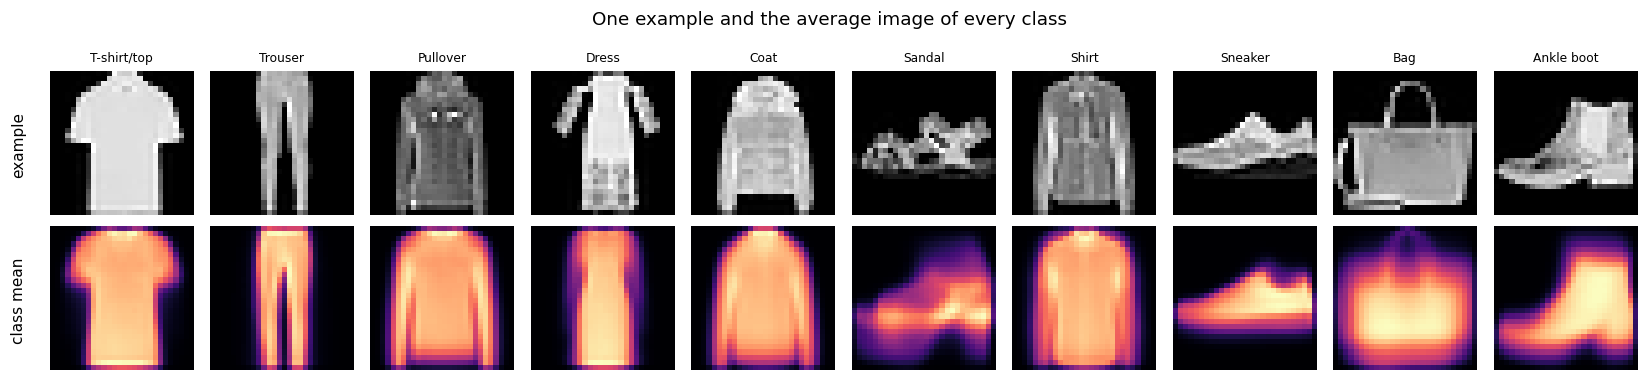

In [ ]:
fig, ax = plt.subplots(2, 10, figsize=(15, 3.6))
for c in range(10):
    ax[0, c].imshow(X_train[y_train == c][0], cmap="gray"); ax[0, c].set_title(CLASSES[c], fontsize=8)
    ax[1, c].imshow(X_train[y_train == c].mean(0), cmap="magma")
    for r in (0, 1): ax[r, c].axis("off")
ax[0, 0].text(-8, 14, "example", rotation=90, va="center"); ax[1, 0].text(-8, 14, "class mean", rotation=90, va="center")
plt.suptitle("One example and the average image of every class"); plt.tight_layout()
plt.savefig(f"{OUT}/01_eda_examples.png", bbox_inches="tight"); plt.show()

In [ ]:
def geo_features(img):
    # shape / geometry / symmetry features of one 28x28 image (values in [0,1])
    m = img > 0.2                                           # silhouette mask
    area = m.mean()
    rows, cols = np.where(m.any(1))[0], np.where(m.any(0))[0]
    if len(rows) == 0: rows = cols = np.array([0])
    bh, bw = rows.max() - rows.min() + 1, cols.max() - cols.min() + 1
    ys, xs = np.mgrid[0:28, 0:28]
    tot = img.sum() + 1e-6
    cy, cx = (img * ys).sum() / tot / 28, (img * xs).sum() / tot / 28
    lr_sym = 1 - np.abs(img - img[:, ::-1]).mean()          # left-right symmetry
    ud_sym = 1 - np.abs(img - img[::-1, :]).mean()          # up-down symmetry
    edge = np.abs(np.diff(img, axis=0)).mean() + np.abs(np.diff(img, axis=1)).mean()
    w_top, w_mid, w_bot = (m[:9].sum(1).mean() / 28, m[9:19].sum(1).mean() / 28, m[19:].sum(1).mean() / 28)
    sleeve = w_top / (w_mid + 1e-6)                         # wide shoulders/sleeves vs body
    leg_gap = 1 - m[18:, 10:18].mean()                      # empty space between legs (trousers)
    base = [area, bh / 28, bw / 28, bw / (bh + 1e-6), area * 784 / (bh * bw), cy, cx, lr_sym, ud_sym,
            img.mean(), img.std(), edge, w_top, w_mid, w_bot, sleeve, leg_gap]
    return np.concatenate([base, img.mean(1), img.mean(0)])  # + 28 row profile + 28 column profile = 73

def hu_features(img):
    hu = moments_hu(moments_normalized(moments_central(img)))
    return -np.sign(hu) * np.log10(np.abs(hu) + 1e-12)      # log-scale: Hu moments span many orders of magnitude

def hog_features(img):
    return hog(img, orientations=9, pixels_per_cell=(7, 7), cells_per_block=(2, 2), block_norm="L2-Hys")

def hogf_features(img):
    return hog(img, orientations=9, pixels_per_cell=(4, 4), cells_per_block=(1, 1), block_norm="L2-Hys")   # 7x7 cells x 9 = 441

def lbp_features(img):
    lbp = local_binary_pattern((img * 255).astype(np.uint8), P=8, R=1, method="uniform")   # codes 0..9
    h = []
    for r in (slice(0, 14), slice(14, 28)):                  # 2x2 spatial grid -> keeps "where" information
        for c in (slice(0, 14), slice(14, 28)):
            b = np.bincount(lbp[r, c].astype(int).ravel(), minlength=10)[:10]
            h.append(b / b.sum())
    return np.concatenate(h)

def extract_all(X, name):
    t0 = time.time()
    out = {g: [] for g in GROUPS}
    for im in X:
        out["hog"].append(hog_features(im)); out["hogf"].append(hogf_features(im)); out["lbp"].append(lbp_features(im))
        out["geo"].append(geo_features(im)); out["hu"].append(hu_features(im))
    out = {k: np.asarray(v, np.float32) for k, v in out.items()}
    print(f"{name}: {len(X)} images -> " + ", ".join(f"{k}:{v.shape[1]}" for k, v in out.items()) + f"  ({time.time()-t0:.0f}s)")
    return out

GROUPS = ["hog", "hogf", "lbp", "geo", "hu"]
cache = f"{OUT}/features_v2{'_quick' if QUICK_TEST else ''}.npz"
if os.path.exists(cache):
    z = np.load(cache); FE = {s: {k: z[f"{s}_{k}"] for k in GROUPS} for s in ["train", "val", "test"]}
    print("loaded cached features from", cache)
else:
    FE = {"train": extract_all(X_train, "train"), "val": extract_all(X_val, "val"), "test": extract_all(X_test, "test")}
    np.savez_compressed(cache, **{f"{s}_{k}": v for s in FE for k, v in FE[s].items()})

loaded cached features from outputs/features_v2.npz


In [ ]:
n = min(3000, len(X_val))
raw = X_val[:n].reshape(n, -1)
eng_scaler = StandardScaler().fit(np.hstack([FE["train"][g] for g in GROUPS]))
eng = eng_scaler.transform(np.hstack([FE["val"][g] for g in GROUPS]))[:n]
res = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, A) in zip(ax, [("Raw pixels (784-d)", raw), ("Engineered features (885-d)", eng)]):
    Z = PCA(50, random_state=0).fit_transform(A)
    res[name] = silhouette_score(Z, y_val[:n])
    E = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(Z)
    sc = a.scatter(E[:, 0], E[:, 1], c=y_val[:n], cmap="tab10", s=4)
    a.set_title(f"{name}\nsilhouette = {res[name]:.3f}"); a.set_xticks([]); a.set_yticks([])
ax[1].legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=7, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.savefig(f"{OUT}/02_tsne_raw_vs_engineered.png", bbox_inches="tight"); plt.show()
print(res)

Raw pixels                     acc=87.36  shirtF1=0.674  (14s)
HOG                            acc=85.58  shirtF1=0.664  (10s)
HOG-F (fine)                   acc=87.78  shirtF1=0.684  (8s)
LBP                            acc=73.58  shirtF1=0.377  (11s)
GEO (shape)                    acc=85.62  shirtF1=0.648  (8s)
HU moments                     acc=64.14  shirtF1=0.301  (8s)
All engineered groups          acc=88.96  shirtF1=0.717  (7s)


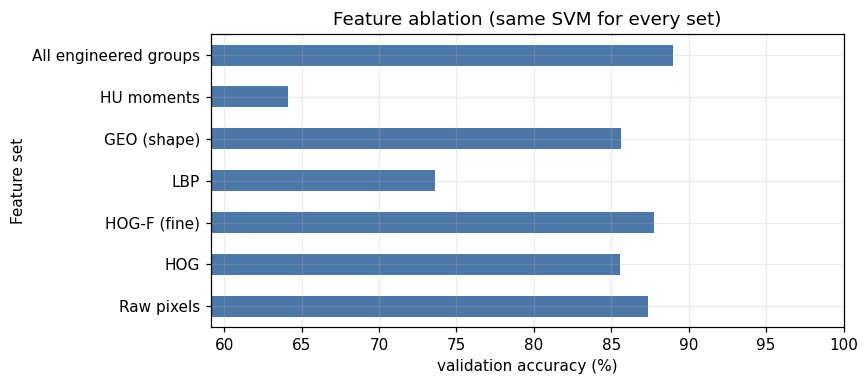

,Feature set,Dims,Val accuracy %,Shirt F1
0,Raw pixels,784,87.36,0.674346
1,HOG,324,85.58,0.663943
2,HOG-F (fine),441,87.78,0.684426
3,LBP,40,73.58,0.377104
4,GEO (shape),73,85.62,0.647541
5,HU moments,7,64.14,0.300842
6,All engineered groups,885,88.96,0.717131


In [ ]:
rs = np.random.RandomState(0)
sub = rs.choice(len(X_train), min(SVM_TRAIN_N, len(X_train)), replace=False)

def feature_matrix(split, groups, Xs):
    if groups == ["pixels"]: return Xs.reshape(len(Xs), -1)
    return np.hstack([FE[split][g] for g in groups])

SETS = {"Raw pixels": ["pixels"], "HOG": ["hog"], "HOG-F (fine)": ["hogf"], "LBP": ["lbp"], "GEO (shape)": ["geo"], "HU moments": ["hu"],
        "All engineered groups": GROUPS}
abl = []
for name, g in SETS.items():
    t0 = time.time()
    A_tr, A_va = feature_matrix("train", g, X_train)[sub], feature_matrix("val", g, X_val)
    sc = StandardScaler().fit(A_tr); pca = PCA(min(64, A_tr.shape[1]), random_state=0).fit(sc.transform(A_tr))
    clf = SVC(kernel="rbf", C=5).fit(pca.transform(sc.transform(A_tr)), y_train[sub])
    p = clf.predict(pca.transform(sc.transform(A_va)))
    abl.append({"Feature set": name, "Dims": A_tr.shape[1], "Val accuracy %": 100 * accuracy_score(y_val, p),
                "Shirt F1": f1_score(y_val, p, labels=[SHIRT], average=None)[0]})
    print(f"{name:30s} acc={abl[-1]['Val accuracy %']:.2f}  shirtF1={abl[-1]['Shirt F1']:.3f}  ({time.time()-t0:.0f}s)")
abl = pd.DataFrame(abl); abl.to_csv(f"{OUT}/feature_ablation.csv", index=False)
ax = abl.set_index("Feature set")["Val accuracy %"].plot.barh(figsize=(8, 3.6), color="#4c78a8")
ax.set_xlabel("validation accuracy (%)"); ax.set_title("Feature ablation (same SVM for every set)")
lo = abl["Val accuracy %"].min(); ax.set_xlim(max(0, lo - 5), 100)
plt.tight_layout(); plt.savefig(f"{OUT}/03_feature_ablation.png", bbox_inches="tight"); plt.show()
abl

In [ ]:
class Backbone(nn.Module):
    # CNN: 3 blocks of (conv-BN-ReLU)x2 + pooling, then global average pooling -> 192 numbers
    def __init__(s, widths=(48, 96, 192)):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(),
                                              nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        w1, w2, w3 = widths; s.out_dim = w3
        s.net = nn.Sequential(block(1, w1), block(w1, w2), block(w2, w3), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.25))
    def forward(s, x):
        return s.net((x - 0.286) / 0.353)                   # normalise with Fashion-MNIST mean/std

class PlainCNN(nn.Module):
    def __init__(s, n_feat=0):
        super().__init__(); s.cnn = Backbone(); s.fc = nn.Linear(s.cnn.out_dim, 10)
    def forward(s, x, f=None): return s.fc(s.cnn(x))

class FusionNet(nn.Module):
    def __init__(s, n_feat):
        super().__init__(); s.cnn = Backbone()
        s.fb = nn.Sequential(nn.Linear(n_feat, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 64), nn.ReLU())
        s.fc = nn.Sequential(nn.Dropout(0.25), nn.Linear(s.cnn.out_dim + 64, 10))
    def forward(s, x, f): return s.fc(torch.cat([s.cnn(x), s.fb(f)], 1))

def n_params(m): return sum(p.numel() for p in m.parameters())

# ---- LIGHT GPU data augmentation ---------------------------------------------------------
def augment_batch(x, max_shift=2, max_rot=5, scale=(0.95, 1.05), cutout=6, cutout_p=0.15):
    B, d = x.size(0), x.device
    ang = (torch.rand(B, device=d) * 2 - 1) * max_rot * math.pi / 180
    sc  = torch.empty(B, device=d).uniform_(*scale)
    sh  = (torch.rand(B, 2, device=d) * 2 - 1) * max_shift * 2 / 28          # 1 pixel = 2/28 in normalised coordinates
    fl  = torch.where(torch.rand(B, device=d) < 0.5, -1.0, 1.0)              # random left-right flip
    c, s_ = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(B, 2, 3, device=d)
    theta[:, 0, 0] = c / sc * fl; theta[:, 0, 1] = -s_ / sc; theta[:, 0, 2] = sh[:, 0]
    theta[:, 1, 0] = s_ / sc * fl; theta[:, 1, 1] = c / sc;  theta[:, 1, 2] = sh[:, 1]
    x = F.grid_sample(x, F.affine_grid(theta, x.size(), align_corners=False), padding_mode="zeros", align_corners=False)
    ar = torch.arange(28, device=d)
    cy, cx = torch.randint(0, 28, (B,), device=d), torch.randint(0, 28, (B,), device=d)
    my = (ar[None] >= (cy - cutout // 2)[:, None]) & (ar[None] < (cy + cutout // 2)[:, None])
    mx = (ar[None] >= (cx - cutout // 2)[:, None]) & (ar[None] < (cx + cutout // 2)[:, None])
    mask = (my[:, :, None] & mx[:, None, :]) & (torch.rand(B, device=d) < cutout_p)[:, None, None]
    return x.masked_fill(mask[:, None], 0.0)

In [ ]:
# ---- prepare tensors (features standardised with TRAIN statistics only) ------------------------
feat_scaler = StandardScaler().fit(np.hstack([FE["train"][g] for g in GROUPS]))
def feats(split): return np.clip(feat_scaler.transform(np.hstack([FE[split][g] for g in GROUPS])), -5, 5).astype(np.float32)
T = lambda a: torch.tensor(a).to(device)
Xtr, Xva, Xte = [T(a[:, None]) for a in (X_train, X_val, X_test)]
Ftr, Fva, Fte = [T(feats(s)) for s in ("train", "val", "test")]
ytr, yva, yte = T(y_train).long(), T(y_val).long(), T(y_test).long()
N_FEAT = Ftr.shape[1]
GROUP_SLICES, o = {}, 0
for g in GROUPS: GROUP_SLICES[g] = slice(o, o + FE["train"][g].shape[1]); o += FE["train"][g].shape[1]
print("feature vector size:", N_FEAT, {g: (s.start, s.stop) for g, s in GROUP_SLICES.items()})

@torch.no_grad()
def predict_proba(model, X, Fe, bs=1024, tta=False):
    # tta=True: average the prediction for the image and for its mirror image (features stay the same)
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb, fb = X[i:i+bs], Fe[i:i+bs]
        p = F.softmax(model(xb, fb).float(), 1)
        if tta: p = (p + F.softmax(model(xb.flip(-1), fb).float(), 1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

def train_model(cls, seed, augment, ls, epochs=EPOCHS, bs=256, lr=3e-3):
    set_seed(seed); model = cls(N_FEAT).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    steps = math.ceil(len(Xtr) / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * steps)
    crit = nn.CrossEntropyLoss(label_smoothing=ls)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)          # mixed precision = faster on GPU
    hist, best, best_state, t0 = [], -1, None, time.time()
    for ep in range(epochs):
        model.train(); idx = torch.randperm(len(Xtr), device=device); tl = 0
        for i in range(0, len(Xtr), bs):
            b = idx[i:i+bs]; xb = augment_batch(Xtr[b]) if augment else Xtr[b]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(xb, Ftr[b]), ytr[b])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(b)
        pv = predict_proba(model, Xva, Fva); va = (pv.argmax(1) == y_val).mean()
        hist.append({"epoch": ep + 1, "train_loss": tl / len(Xtr), "val_acc": va})
        if va > best: best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
    train_time = time.time() - t0
    model.load_state_dict(best_state)                        # keep the epoch that was best on VALIDATION
    return model, pd.DataFrame(hist), train_time

# ---- metrics and calibration helpers ---------------------------------------------------------
def ece_score(p, y, bins=15):
    # Expected Calibration Error: gap between confidence and real accuracy (0 = perfectly honest confidence)
    conf, pred = p.max(1), p.argmax(1); ok = (pred == y).astype(float); e = 0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

def nll_of(p, y): return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

def metrics(p, y):
    pred = p.argmax(1)
    return {"acc": 100 * accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"), "nll": nll_of(p, y), "ece": ece_score(p, y)}

def apply_temperature(p, Tm):
    z = np.log(p + 1e-12) / Tm; z -= z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def fit_temperature(p_val, y):
    # temperature scaling: ONE number T fitted on the validation set that rescales confidence (never changes accuracy)
    grid = np.linspace(0.5, 3.0, 126)
    return float(grid[int(np.argmin([nll_of(apply_temperature(p_val, t), y) for t in grid]))])

feature vector size: 885 {'hog': (0, 324), 'hogf': (324, 765), 'lbp': (765, 805), 'geo': (805, 878), 'hu': (878, 885)}


In [ ]:
NAME_A, NAME_A2, NAME_B, NAME_C = "A. CNN (baseline)", "A2. CNN + features", "B. CNN + light Aug + LS", "C. FusionNet (ours)"
RECIPES = {
    NAME_A:  dict(cls=PlainCNN,  augment=False, ls=0.0),
    NAME_A2: dict(cls=FusionNet, augment=False, ls=0.0),
    NAME_B:  dict(cls=PlainCNN,  augment=True,  ls=0.05),
    NAME_C:  dict(cls=FusionNet, augment=True,  ls=0.05),
}
runs, models, P_test, P_val, histories = [], {}, {}, {}, {}
for name, cfg in RECIPES.items():
    for seed in SEEDS:
        model, hist, tt = train_model(cfg["cls"], seed, cfg["augment"], cfg["ls"])
        tta = cfg["augment"]                                  # mirror-TTA only for models that were trained with flips
        pt, pv = predict_proba(model, Xte, Fte, tta=tta), predict_proba(model, Xva, Fva, tta=tta)
        plain_acc = 100 * (predict_proba(model, Xte, Fte).argmax(1) == y_test).mean()
        t0 = time.time(); predict_proba(model, Xte, Fte); inf_ms = 1000 * (time.time() - t0) / len(Xte)
        m = metrics(pt, y_test); m.update(model=name, seed=seed, acc_no_tta=plain_acc, params_M=n_params(model) / 1e6,
                                          train_s=tt, infer_ms=inf_ms, best_val=100 * hist.val_acc.max())
        runs.append(m); models[(name, seed)] = model; P_test[(name, seed)] = pt; P_val[(name, seed)] = pv; histories[(name, seed)] = hist
        print(f"{name:24s} seed {seed}: test acc {m['acc']:.2f} (no TTA {plain_acc:.2f})  F1 {m['macro_f1']:.4f}  ECE {m['ece']:.4f}  ({tt:.0f}s)")
runs = pd.DataFrame(runs); runs.to_csv(f"{OUT}/all_runs.csv", index=False)

A. CNN (baseline)        seed 0: test acc 93.76 (no TTA 93.76)  F1 0.9375  ECE 0.0449  (107s)
A. CNN (baseline)        seed 1: test acc 93.83 (no TTA 93.83)  F1 0.9380  ECE 0.0423  (117s)
A. CNN (baseline)        seed 2: test acc 93.80 (no TTA 93.80)  F1 0.9378  ECE 0.0448  (114s)
A2. CNN + features       seed 0: test acc 93.76 (no TTA 93.76)  F1 0.9375  ECE 0.0446  (115s)
A2. CNN + features       seed 1: test acc 93.66 (no TTA 93.66)  F1 0.9361  ECE 0.0455  (115s)
A2. CNN + features       seed 2: test acc 93.11 (no TTA 93.11)  F1 0.9309  ECE 0.0495  (115s)
B. CNN + light Aug + LS  seed 0: test acc 94.29 (no TTA 94.04)  F1 0.9429  ECE 0.0346  (117s)
B. CNN + light Aug + LS  seed 1: test acc 94.45 (no TTA 94.21)  F1 0.9445  ECE 0.0389  (117s)
B. CNN + light Aug + LS  seed 2: test acc 94.30 (no TTA 94.09)  F1 0.9430  ECE 0.0353  (116s)
C. FusionNet (ours)      seed 0: test acc 92.68 (no TTA 92.70)  F1 0.9266  ECE 0.0222  (119s)
C. FusionNet (ours)      seed 1: test acc 92.84 (no TTA 92.7

In [ ]:
agg = runs.groupby("model").agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), acc_no_tta=("acc_no_tta", "mean"),
                                f1_mean=("macro_f1", "mean"), ece_mean=("ece", "mean"), nll_mean=("nll", "mean"),
                                params_M=("params_M", "first"), train_s=("train_s", "mean"), infer_ms=("infer_ms", "mean")).fillna(0)
agg.round(4)

,acc_mean,acc_std,acc_no_tta,f1_mean,ece_mean,nll_mean,params_M,train_s,infer_ms
model,,,,,,,,,
A. CNN (baseline),93.7967,0.0351,93.7967,0.9378,0.0440,0.3142,0.6465,112.6366,0.0485
A2. CNN + features,93.5100,0.3500,93.5100,0.9348,0.0466,0.3264,0.7691,114.8996,0.0486
B. CNN + light Aug + LS,94.3467,0.0896,94.1133,0.9435,0.0363,0.1910,0.6465,116.7539,0.0484
C. FusionNet (ours),92.8200,0.1311,92.7933,0.9280,0.0220,0.2426,0.7691,119.1397,0.0490


In [ ]:
def ens(P, keys): return np.mean([P[k] for k in keys], 0)
ENS_KEYS = {"C+. FusionNet ensemble (seeds)": [k for k in P_test if k[0] == NAME_C],
            "D. Ensemble B + C (all aug models)": [k for k in P_test if k[0] in (NAME_B, NAME_C)]}
ens_test = {n: ens(P_test, k) for n, k in ENS_KEYS.items()}
ens_val  = {n: ens(P_val, k)  for n, k in ENS_KEYS.items()}
ens_rows = []
for n_ in ENS_KEYS:
    m = metrics(ens_test[n_], y_test); m.update(model=n_, val_acc=100 * (ens_val[n_].argmax(1) == y_val).mean()); ens_rows.append(m)
    print(f"{n_:38s} val {m['val_acc']:.2f} | test acc {m['acc']:.2f}  F1 {m['macro_f1']:.4f}  ECE {m['ece']:.4f}")
ens_df = pd.DataFrame(ens_rows)
FINAL_NAME = ens_df.sort_values("val_acc", ascending=False).iloc[0]["model"]        # chosen on VALIDATION accuracy
final_p, final_pv = ens_test[FINAL_NAME], ens_val[FINAL_NAME]
print("\nFinal model (chosen on validation):", FINAL_NAME)

C+. FusionNet ensemble (seeds)         val 93.76 | test acc 93.11  F1 0.9309  ECE 0.0274
D. Ensemble B + C (all aug models)     val 94.74 | test acc 94.30  F1 0.9429  ECE 0.0431

Final model (chosen on validation): D. Ensemble B + C (all aug models)


In [ ]:
phase1 = pd.DataFrame([
    ["CNN (Phase 1)",        93.96, 0.939, 0.585, 126, "Phase 1"],
    ["ResNet (Phase 1)",     93.48, 0.935, 2.80,  255, "Phase 1"],
    ["ViT (Phase 1)",        89.75, 0.898, 0.81,  205, "Phase 1"],
    ["VAE + Head (Phase 1)", 84.75, 0.846, 1.71,  272, "Phase 1"]],
    columns=["Model", "Test acc %", "Macro F1", "Params (M)", "Train time (s)", "Source"])
rows = []
for name, r in agg.iterrows():
    rows.append([name, f"{r.acc_mean:.2f} ± {r.acc_std:.2f}", round(r.f1_mean, 4), round(r.params_M, 3), round(r.train_s), "Phase 2"])
ri = runs.set_index(["model", "seed"])
for _, r in ens_df.iterrows():
    sub_ = ri.loc[ENS_KEYS[r.model]]
    rows.append([r.model + ("  <- final" if r.model == FINAL_NAME else ""), f"{r.acc:.2f}", round(r.macro_f1, 4), round(sub_.params_M.sum(), 3), round(sub_.train_s.sum()), "Phase 2"])
final = pd.concat([phase1.assign(**{"Test acc %": phase1["Test acc %"].map("{:.2f}".format)}),
                   pd.DataFrame(rows, columns=phase1.columns)], ignore_index=True)
final.to_csv(f"{OUT}/final_comparison.csv", index=False); final

,Model,Test acc %,Macro F1,Params (M),Train time (s),Source
0,CNN (Phase 1),93.96,0.9390,0.585,126,Phase 1
1,ResNet (Phase 1),93.48,0.9350,2.800,255,Phase 1
2,ViT (Phase 1),89.75,0.8980,0.810,205,Phase 1
3,VAE + Head (Phase 1),84.75,0.8460,1.710,272,Phase 1
4,A. CNN (baseline),93.80 ± 0.04,0.9378,0.647,113,Phase 2
5,A2. CNN + features,93.51 ± 0.35,0.9348,0.769,115,Phase 2
6,B. CNN + light Aug + LS,94.35 ± 0.09,0.9435,0.647,117,Phase 2
7,C. FusionNet (ours),92.82 ± 0.13,0.9280,0.769,119,Phase 2
8,C+. FusionNet ensemble (seeds),93.11,0.9309,2.307,357,Phase 2
9,D. Ensemble B + C (all aug models) <- final,94.30,0.9429,4.247,708,Phase 2


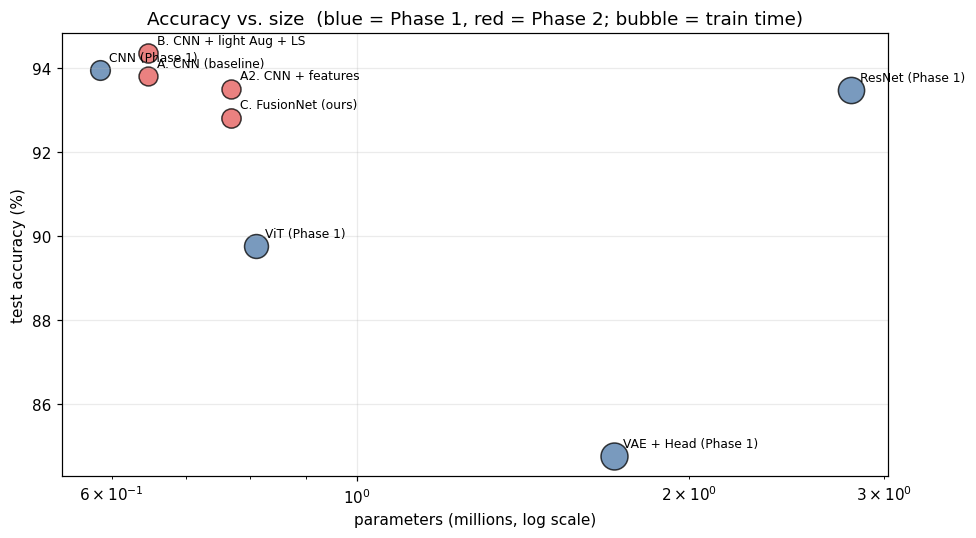

In [ ]:
# Accuracy vs. model size  (bigger bubble = longer training)
pts = [(r["Model"], float(str(r["Test acc %"]).split()[0]), r["Params (M)"], r["Train time (s)"], r["Source"]) for _, r in final.iterrows()
       if "ensemble" not in r["Model"].lower()]
fig, ax = plt.subplots(figsize=(9, 5))
for n_, a, p, t, s_ in pts:
    ax.scatter(p, a, s=t * 1.0 + 40, color="#e45756" if s_ == "Phase 2" else "#4c78a8", alpha=.75, edgecolor="k")
    ax.annotate(n_, (p, a), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("parameters (millions, log scale)"); ax.set_ylabel("test accuracy (%)")
ax.set_title("Accuracy vs. size  (blue = Phase 1, red = Phase 2; bubble = train time)")
plt.tight_layout(); plt.savefig(f"{OUT}/04_accuracy_vs_size.png", bbox_inches="tight"); plt.show()

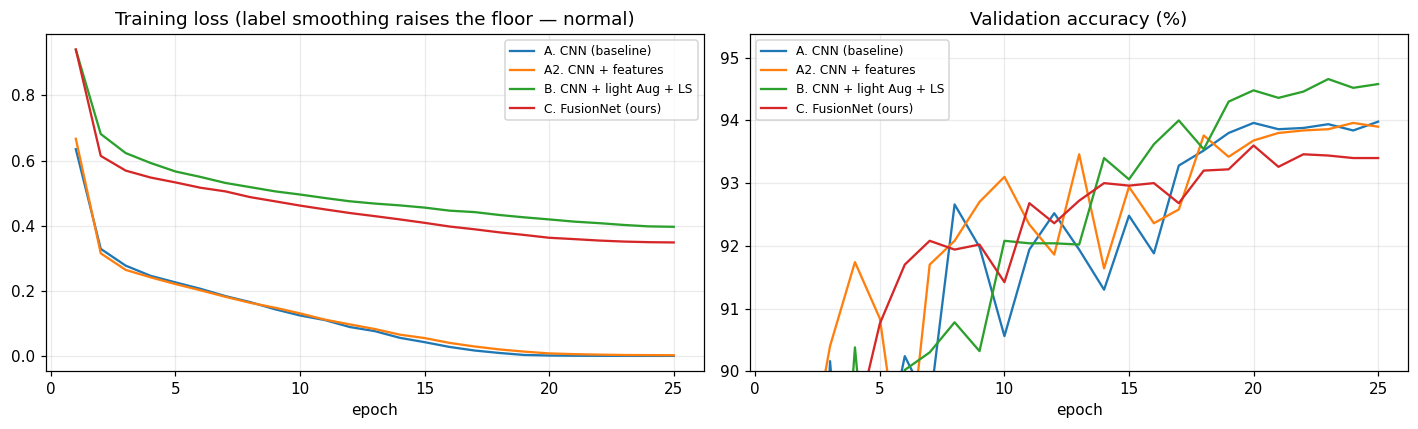

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in RECIPES:
    h = histories[(name, SEEDS[0])]
    ax[0].plot(h.epoch, h.train_loss, label=name); ax[1].plot(h.epoch, 100 * h.val_acc, label=name)
ax[0].set_title("Training loss (label smoothing raises the floor — normal)"); ax[1].set_title("Validation accuracy (%)")
ax[1].set_ylim(90, None)
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/05_training_curves.png", bbox_inches="tight"); plt.show()

In [ ]:
def mcnemar(pa, pb, y):
    a_ok, b_ok = pa.argmax(1) == y, pb.argmax(1) == y
    n10, n01 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())        # A right/B wrong ; A wrong/B right
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 > 0 else 1.0
    return n10, n01, p

s0 = SEEDS[0]; base_p = P_test[(NAME_A, s0)]
pairs = [("A vs A2   : features alone",              P_test[(NAME_A, s0)],  P_test[(NAME_A2, s0)]),
         ("A vs B    : light aug + LS alone",         P_test[(NAME_A, s0)],  P_test[(NAME_B, s0)]),
         ("B vs C    : features on top of aug + LS",  P_test[(NAME_B, s0)],  P_test[(NAME_C, s0)]),
         ("A2 vs C   : aug + LS on top of features",  P_test[(NAME_A2, s0)], P_test[(NAME_C, s0)]),
         ("A vs FINAL: baseline vs final model",      base_p,                final_p)]
rows = []
for k, pa, pb in pairs:
    n10, n01, p = mcnemar(pa, pb, y_test)
    rows.append({"comparison": k, "only first correct": n10, "only second correct": n01, "p-value": p, "significant (p<0.05)": p < 0.05})
mc = pd.DataFrame(rows); mc.to_csv(f"{OUT}/mcnemar.csv", index=False); mc

,comparison,only first correct,only second correct,p-value,significant (p<0.05)
0,A vs A2 : features alone,207,207,1.000000e+00,False
1,A vs B : light aug + LS alone,175,228,9.503759e-03,True
2,B vs C : features on top of aug + LS,325,164,2.848850e-13,True
3,A2 vs C : aug + LS on top of features,258,150,9.967108e-08,True
4,A vs FINAL: baseline vs final model,171,225,7.658025e-03,True


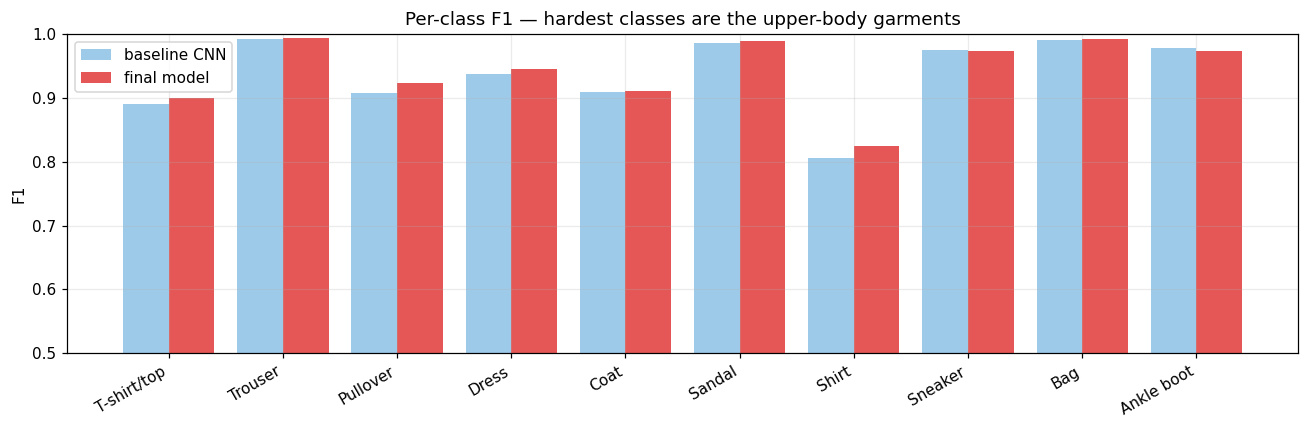

,class,F1 baseline CNN,F1 final model,change
0,T-shirt/top,0.891,0.900,0.009
1,Trouser,0.992,0.994,0.002
2,Pullover,0.908,0.924,0.016
3,Dress,0.938,0.945,0.008
4,Coat,0.910,0.911,0.002
5,Sandal,0.986,0.989,0.003
6,Shirt,0.807,0.825,0.018
7,Sneaker,0.975,0.974,-0.001
8,Bag,0.991,0.993,0.002
9,Ankle boot,0.978,0.974,-0.004


In [ ]:
f1_base = f1_score(y_test, base_p.argmax(1), average=None); f1_fin = f1_score(y_test, final_p.argmax(1), average=None)
pc = pd.DataFrame({"class": CLASSES, "F1 baseline CNN": f1_base, "F1 final model": f1_fin, "change": f1_fin - f1_base})
pc.to_csv(f"{OUT}/per_class_f1.csv", index=False)
x = np.arange(10); fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(x - .2, f1_base, .4, label="baseline CNN", color="#9ecae9"); ax.bar(x + .2, f1_fin, .4, label="final model", color="#e45756")
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=30, ha="right"); ax.set_ylim(.5, 1); ax.set_ylabel("F1"); ax.legend()
ax.set_title("Per-class F1 — hardest classes are the upper-body garments")
plt.tight_layout(); plt.savefig(f"{OUT}/06_per_class_f1.png", bbox_inches="tight"); plt.show()
pc.round(3)

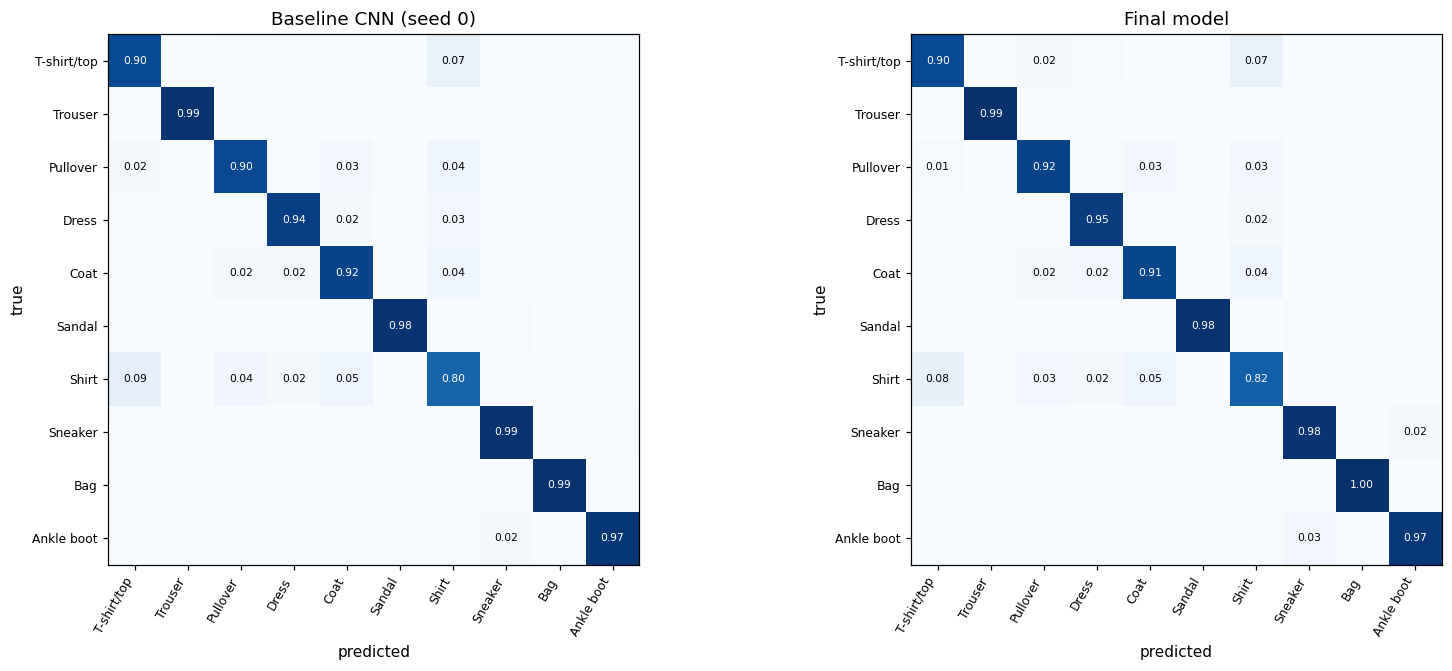

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2))
for a, (title, p) in zip(ax, [("Baseline CNN (seed 0)", base_p), ("Final model", final_p)]):
    cm = confusion_matrix(y_test, p.argmax(1), normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1); a.grid(False)
    a.set_xticks(range(10)); a.set_yticks(range(10)); a.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8); a.set_yticklabels(CLASSES, fontsize=8)
    for i in range(10):
        for j in range(10):
            if cm[i, j] >= 0.015: a.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > .5 else "black")
    a.set_title(title); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig(f"{OUT}/07_confusion_matrices.png", bbox_inches="tight"); plt.show()

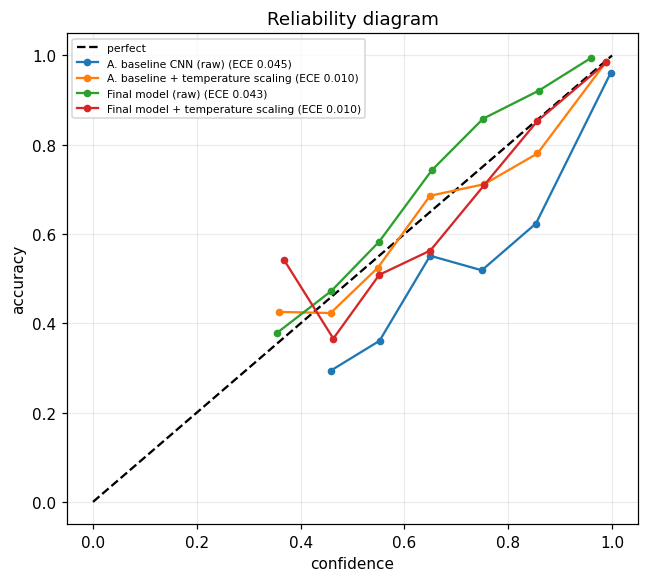

fitted temperatures: baseline T=2.44, final T=0.70


,model,accuracy %,ECE,NLL
0,A. baseline CNN (raw),93.76,0.0449,0.3160
1,A. baseline + temperature scaling,93.76,0.0102,0.1884
2,Final model (raw),94.30,0.0431,0.1932
3,Final model + temperature scaling,94.30,0.0101,0.1640


In [ ]:
T_final = fit_temperature(final_pv, y_val); T_base = fit_temperature(P_val[(NAME_A, s0)], y_val)
cal = {"A. baseline CNN (raw)": base_p, "A. baseline + temperature scaling": apply_temperature(base_p, T_base),
       "Final model (raw)": final_p,   "Final model + temperature scaling": apply_temperature(final_p, T_final)}
cal_df = pd.DataFrame([{"model": k, "accuracy %": 100 * (p.argmax(1) == y_test).mean(), "ECE": ece_score(p, y_test), "NLL": nll_of(p, y_test)} for k, p in cal.items()])
cal_df.to_csv(f"{OUT}/calibration.csv", index=False)
def reliability(p, y, bins=10):
    conf, ok = p.max(1), (p.argmax(1) == y).astype(float); edges = np.linspace(0, 1, bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 10: xs.append(conf[m].mean()); ys.append(ok[m].mean())
    return xs, ys
fig, ax = plt.subplots(figsize=(6, 5.4)); ax.plot([0, 1], [0, 1], "k--", label="perfect")
for lab, p in cal.items():
    xs, ys = reliability(p, y_test); ax.plot(xs, ys, "o-", ms=4, label=f"{lab} (ECE {ece_score(p, y_test):.3f})")
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(fontsize=7); ax.set_title("Reliability diagram")
plt.tight_layout(); plt.savefig(f"{OUT}/08_reliability.png", bbox_inches="tight"); plt.show()
print(f"fitted temperatures: baseline T={T_base:.2f}, final T={T_final:.2f}"); cal_df.round(4)

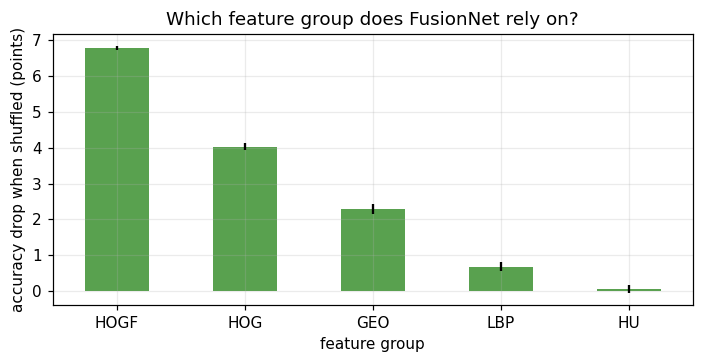

,feature group,accuracy drop (pts),std
1,HOGF,6.776667,0.047842
0,HOG,4.030000,0.092736
3,GEO,2.296667,0.135728
2,LBP,0.683333,0.122837
4,HU,0.063333,0.110252


In [ ]:
fm = models[(NAME_C, s0)]
base_acc = 100 * (predict_proba(fm, Xte, Fte).argmax(1) == y_test).mean()
g = torch.Generator(device="cpu").manual_seed(0); imp = []
for gname, sl in GROUP_SLICES.items():
    drops = []
    for rep in range(3):
        Fp = Fte.clone(); Fp[:, sl] = Fte[torch.randperm(len(Fte), generator=g).to(device)][:, sl]
        drops.append(base_acc - 100 * (predict_proba(fm, Xte, Fp).argmax(1) == y_test).mean())
    imp.append({"feature group": gname.upper(), "accuracy drop (pts)": np.mean(drops), "std": np.std(drops)})
imp = pd.DataFrame(imp).sort_values("accuracy drop (pts)", ascending=False); imp.to_csv(f"{OUT}/permutation_importance.csv", index=False)
ax = imp.set_index("feature group")["accuracy drop (pts)"].plot.bar(yerr=imp["std"].values, figsize=(6.5, 3.4), color="#59a14f", rot=0)
ax.set_ylabel("accuracy drop when shuffled (points)"); ax.set_title("Which feature group does FusionNet rely on?")
plt.tight_layout(); plt.savefig(f"{OUT}/09_permutation_importance.png", bbox_inches="tight"); plt.show(); imp

Most frequent confusions (final model):
  true Shirt        -> predicted T-shirt/top  : 79 images
  true T-shirt/top  -> predicted Shirt        : 74 images
  true Shirt        -> predicted Coat         : 50 images
  true Coat         -> predicted Shirt        : 41 images
  true Shirt        -> predicted Pullover     : 31 images
  true Pullover     -> predicted Shirt        : 28 images


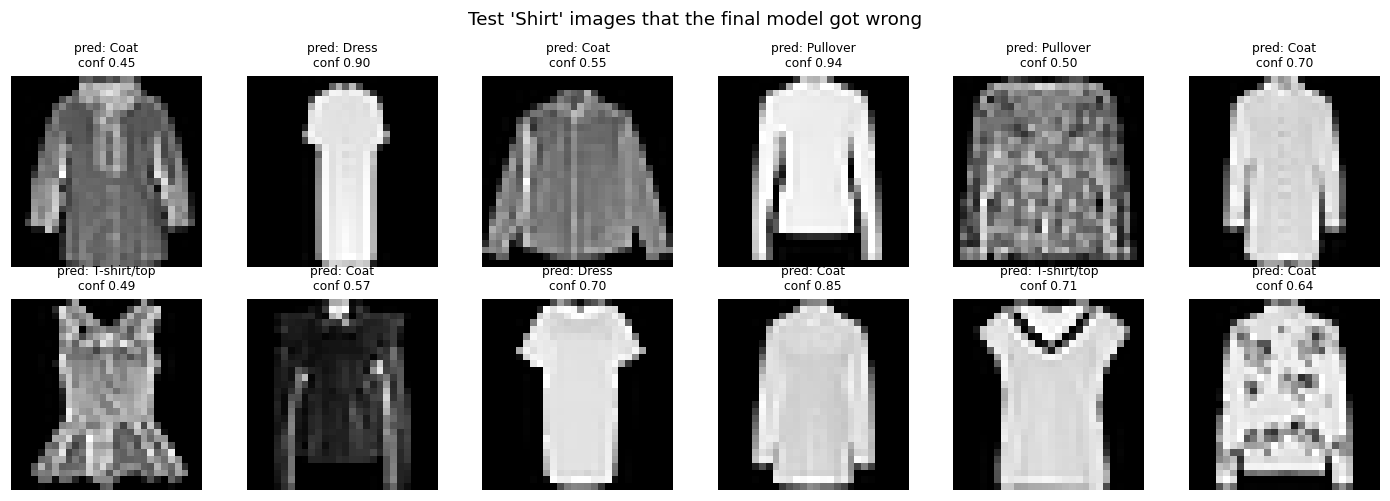

In [ ]:
pred_f = final_p.argmax(1)
cm = confusion_matrix(y_test, pred_f); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:6], cm.shape))[0]
print("Most frequent confusions (final model):")
for i, j in top: print(f"  true {CLASSES[i]:12s} -> predicted {CLASSES[j]:12s} : {cm[i, j]} images")
wrong = np.where((y_test == SHIRT) & (pred_f != SHIRT))[0][:12]
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for a, i in zip(ax.ravel(), wrong):
    a.imshow(X_test[i], cmap="gray"); a.set_title(f"pred: {CLASSES[pred_f[i]]}\nconf {final_p[i].max():.2f}", fontsize=8); a.axis("off")
for a in ax.ravel()[len(wrong):]: a.axis("off")
plt.suptitle("Test 'Shirt' images that the final model got wrong"); plt.tight_layout()
plt.savefig(f"{OUT}/10_shirt_errors.png", bbox_inches="tight"); plt.show()

In [ ]:
torch.save(models[(NAME_C, s0)].state_dict(), f"{OUT}/fusionnet_seed0.pt")
json.dump({"EPOCHS": EPOCHS, "SEEDS": SEEDS, "final_model": FINAL_NAME, "temperature_final": T_final,
           "split": "55000/5000/10000, permutation seed 42"}, open(f"{OUT}/config.json", "w"))

a, a2, b, c = (agg.loc[n] for n in (NAME_A, NAME_A2, NAME_B, NAME_C))
fe = ens_df.set_index("model").loc[FINAL_NAME]
pv = lambda key: mc.loc[mc.comparison.str.startswith(key), "p-value"].iloc[0]
sig = lambda p: "significant" if p < 0.05 else "NOT significant at 5 %"
print("=" * 82)
print(f"A.  baseline CNN                       : {a.acc_mean:.2f} ± {a.acc_std:.2f} %   ECE {a.ece_mean:.3f}")
print(f"A2. + engineered features only          : {a2.acc_mean:.2f} ± {a2.acc_std:.2f} %   ({a2.acc_mean-a.acc_mean:+.2f} pts, McNemar p={pv('A vs A2'):.3f}, {sig(pv('A vs A2'))})")
print(f"B.  + light augmentation + smoothing    : {b.acc_mean:.2f} ± {b.acc_std:.2f} %   ({b.acc_mean-a.acc_mean:+.2f} pts, McNemar p={pv('A vs B'):.3f}, {sig(pv('A vs B'))})")
print(f"C.  FusionNet (features + aug + LS)     : {c.acc_mean:.2f} ± {c.acc_std:.2f} %   ({c.acc_mean-a.acc_mean:+.2f} pts vs A; {c.acc_mean-b.acc_mean:+.2f} pts vs B, p={pv('B vs C'):.3f}, {sig(pv('B vs C'))})")
print(f"FINAL ({FINAL_NAME}): {fe.acc:.2f} %  macro-F1 {fe.macro_f1:.4f}")
print(f"   gain over baseline A: {fe.acc - a.acc_mean:+.2f} pts, McNemar p = {pv('A vs FINAL'):.4f} ({sig(pv('A vs FINAL'))})")
print(f"   Shirt-class F1 change vs baseline: {pc.loc[pc['class'] == 'Shirt', 'change'].iloc[0]:+.3f}")
print(f"   Most-used feature group (permutation): {imp.iloc[0]['feature group']} (drop {imp.iloc[0]['accuracy drop (pts)']:.2f} pts)")
cr = cal_df.set_index("model")["ECE"]
print(f"   ECE of final model: {cr['Final model (raw)']:.3f} raw -> {cr['Final model + temperature scaling']:.3f} after temperature scaling")
print("=" * 82)
if not QUICK_TEST:
    shutil.make_archive("final_project_outputs", "zip", OUT); print("All results zipped -> final_project_outputs.zip (download from the Files panel)")

A.  baseline CNN                       : 93.80 ± 0.04 %   ECE 0.044
A2. + engineered features only          : 93.51 ± 0.35 %   (-0.29 pts, McNemar p=1.000, NOT significant at 5 %)
B.  + light augmentation + smoothing    : 94.35 ± 0.09 %   (+0.55 pts, McNemar p=0.010, significant)
C.  FusionNet (features + aug + LS)     : 92.82 ± 0.13 %   (-0.98 pts vs A; -1.53 pts vs B, p=0.000, significant)
FINAL (D. Ensemble B + C (all aug models)): 94.30 %  macro-F1 0.9429
   gain over baseline A: +0.50 pts, McNemar p = 0.0077 (significant)
   Shirt-class F1 change vs baseline: +0.018
   Most-used feature group (permutation): HOGF (drop 6.78 pts)
   ECE of final model: 0.043 raw -> 0.010 after temperature scaling
All results zipped -> final_project_outputs.zip (download from the Files panel)
